# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

**Student Name:** Adarsh Shivanand Madli  
**SRN:** PES2UG24CS028  
**Course:** UE24CS342AA9 — Visualization of Data and User Interfaces (VDUI)  

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB (MB = 1024^2 bytes as in Demo Cell 27)
MB = 1024 ** 2
frame_mb = (1920 * 1080 * 3) / MB

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 24 * 3600 * FPS

# TODO 3: 400 cameras x 24 h, uncompressed, in TB (1 TB = 1024⁴ bytes)
fleet_tb = (400 * frames_per_day * (1920 * 1080 * 3)) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frames_per_day_small = 24 * 3600 * 10
frame_bytes_small = 640 * 360 * 3
fleet_tb_small = (400 * frames_per_day_small * frame_bytes_small) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

* **Spatial Evidence Lost (Slide 13 — Raster Interpolation & Spatial Resolution):**  
  Downsampling from 1080p (1920×1080) to 360p (640×360) retains only $1/9 \approx 11.11\%$ of the original pixels, permanently discarding $88.89\%$ of spatial data. Fine high-frequency spatial features—such as vehicle license plate numbers, distinctive facial features of the suspect, or small tools held in hand—are irretrievably lost. When the lower-resolution raster is enlarged, raster interpolation (bilinear or nearest-neighbor) simply blurs or pixelates the image, creating staircased edges and unrecoverable detail.

* **Temporal Evidence Lost (Slides 36–37 — Frame Rate & The Correspondence Problem):**  
  Reducing the frame rate from 30 fps to 10 fps triples the inter-frame sampling interval from 33.3 ms to 100 ms. Rapid transient events—such as the exact millisecond impact of the strike on the glass or the initial scattering of shards—are skipped entirely. Furthermore, when the perpetrator accelerates into a sprint (~35.6 px/s), large inter-frame displacements produce the **correspondence problem**, where tracking algorithms and human viewers cannot definitively match the object's identity and boundaries across successive frames without ambiguity.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

Contrast before: 0.609  ->  after: 1.000


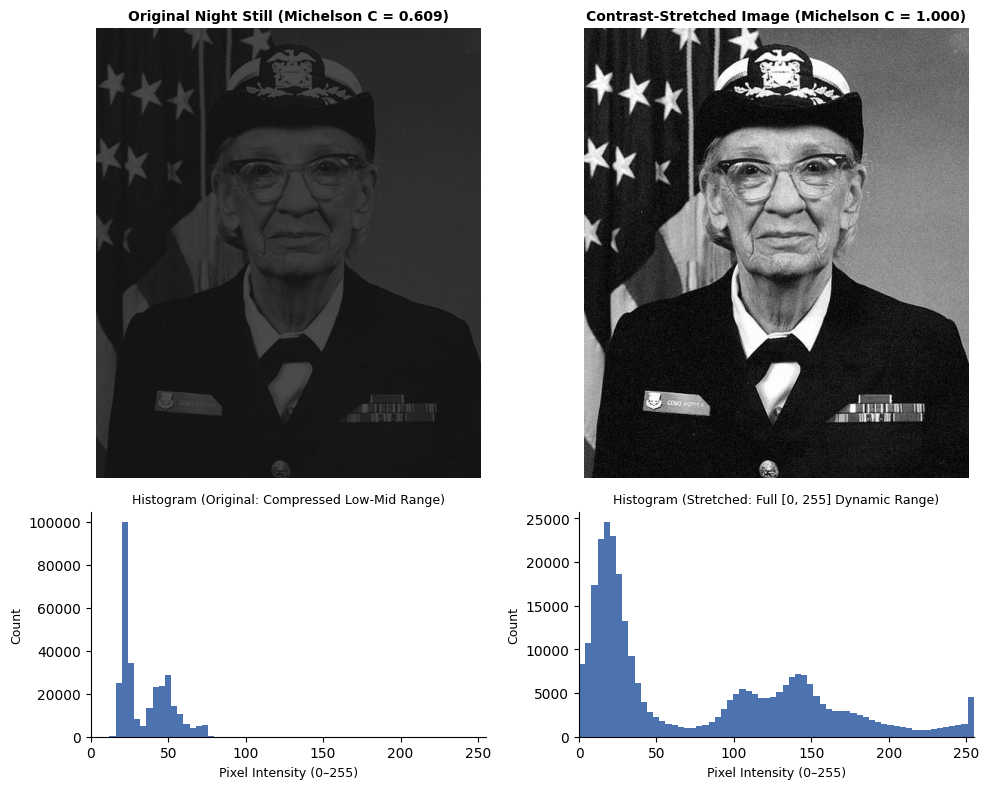

In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)

p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title(f"Original Night Still (Michelson C = {c_before:.3f})", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title(f"Contrast-Stretched Image (Michelson C = {c_after:.3f})", fontsize=10, fontweight='bold')
axes[0, 1].axis('off')

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='#4C72B0', edgecolor='none')
axes[1, 0].set_title("Histogram (Original: Compressed Low-Mid Range)", fontsize=9)
axes[1, 0].set_xlabel("Pixel Intensity (0–255)", fontsize=9)
axes[1, 0].set_ylabel("Count", fontsize=9)
axes[1, 0].set_xlim(0, 255)

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='#4C72B0', edgecolor='none')
axes[1, 1].set_title("Histogram (Stretched: Full [0, 255] Dynamic Range)", fontsize=9)
axes[1, 1].set_xlabel("Pixel Intensity (0–255)", fontsize=9)
axes[1, 1].set_ylabel("Count", fontsize=9)
axes[1, 1].set_xlim(0, 255)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

* **Histogram Shape (Slide 18 vocabulary):**  
  The night image histogram is **narrow, unimodal, and low-contrast**, heavily compressed into a tight band between intensities ~18 and ~73. It completely lacks true blacks/shadows (zero counts from 0 to 17) and completely lacks midtones and highlights (zero counts from 74 to 255).

* **Why Contrast Stretching Makes It Readable Without Adding Information:**  
  Stretching applies a linear remapping: $I_{\text{out}} = \text{clip}\left(\frac{I_{\text{in}} - P_1}{P_{99} - P_1} \times 255, 0, 255\right)$. It introduces zero new information (information entropy is unchanged) and creates no new intensity gradations. However, it expands the occupied range across the full $[0, 255]$ dynamic range of the display. This amplifies the luminance gradients between adjacent pixels past the human visual system's *Just Noticeable Difference (JND)* threshold, transforming an imperceptible murky wash into clear perceptual contours and facial/structural features.

* **Why Histogram Alone Cannot Reveal Content ("Same Histogram ≠ Same Image"):**  
  A histogram is a 1D, zero-order frequency distribution that records *how many* pixels have a given intensity while completely discarding their spatial $(x, y)$ coordinates. As demonstrated in Slide 18, shuffling the pixels of Grace Hopper's portrait produces an identical histogram but results in complete visual white noise. Image semantics, structure, edges, and object recognition depend entirely on spatial topology and pixel spatial relationships.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing time range: 68.70 s to 78.10 s
Running time range:  78.60 s to 86.00 s
Audio event (> -20 dB): frame 2250 at 75.00 s (-4.6 dB)
Lighting event (> +40):  frame 3000 at 100.00 s (+86.0 jump)


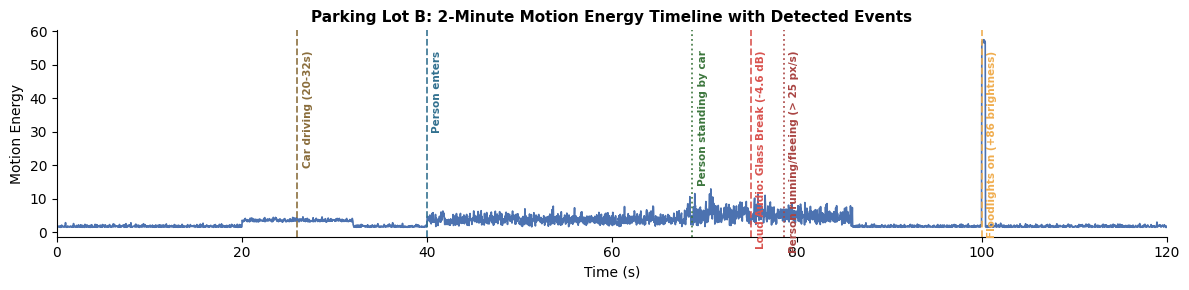

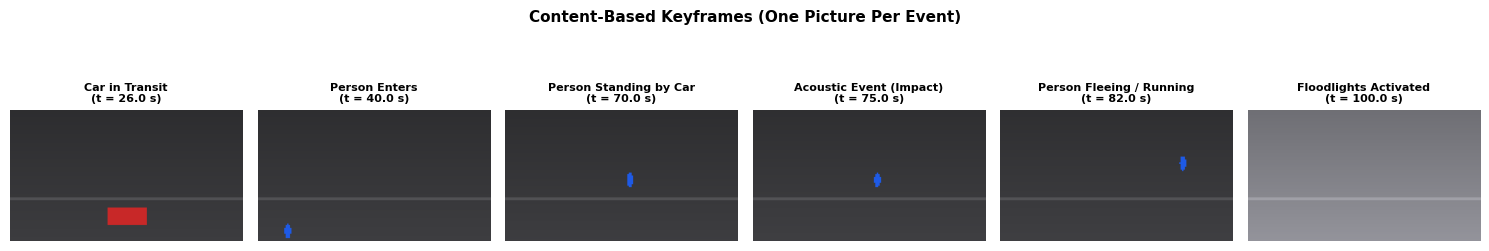

In [4]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))
cctv['speed'] = speed

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = cctv[cctv['speed'] < 3.0]
running = cctv[cctv['speed'] > 25.0]

print(f"Standing time range: {standing['time_s'].iloc[0]:.2f} s to {standing['time_s'].iloc[-1]:.2f} s")
print(f"Running time range:  {running['time_s'].iloc[0]:.2f} s to {running['time_s'].iloc[-1]:.2f} s")

# TODO 3: event frame indices
loud = cctv.index[(cctv.audio_level_db > -20) & (cctv.audio_level_db.shift() <= -20)]
audio_event_idx = loud[0]

glob = cctv.index[cctv.mean_brightness.diff() > 40]
lighting_event_idx = glob[0]

print(f"Audio event (> -20 dB): frame {audio_event_idx} at {cctv.time_s[audio_event_idx]:.2f} s ({cctv.audio_level_db[audio_event_idx]:.1f} dB)")
print(f"Lighting event (> +40):  frame {lighting_event_idx} at {cctv.time_s[lighting_event_idx]:.2f} s (+{cctv.mean_brightness.diff()[lighting_event_idx]:.1f} jump)")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color='#4C72B0', lw=1.2, label='Motion Energy')

# Mark key events
event_markers = [
    (26.0, 'Car driving (20-32s)', '#8A6D3B', '--'),
    (40.0, 'Person enters', '#31708F', '--'),
    (standing['time_s'].iloc[0], 'Person standing by car', '#3C763D', ':'),
    (cctv.time_s[audio_event_idx], 'Loud Audio: Glass Break (-4.6 dB)', '#D9534F', '--'),
    (running['time_s'].iloc[0], 'Person running/fleeing (> 25 px/s)', '#A94442', ':'),
    (cctv.time_s[lighting_event_idx], 'Floodlights on (+86 brightness)', '#F0AD4E', '--')
]
for t_val, label, col, ls in event_markers:
    ax.axvline(t_val, color=col, linestyle=ls, lw=1.3, alpha=0.9)
    ax.text(t_val + 0.6, ax.get_ylim()[1] * 0.90, label, rotation=90, va='top', fontsize=7.5, color=col, fontweight='bold')

ax.set_xlim(0, 120)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Motion Energy')
ax.set_title('Parking Lot B: 2-Minute Motion Energy Timeline with Detected Events', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
keyframes = [
    (780, 'Car in Transit\n(t = 26.0 s)'),
    (1200, 'Person Enters\n(t = 40.0 s)'),
    (2100, 'Person Standing by Car\n(t = 70.0 s)'),
    (audio_event_idx, f'Acoustic Event (Impact)\n(t = {cctv.time_s[audio_event_idx]:.1f} s)'),
    (2460, 'Person Fleeing / Running\n(t = 82.0 s)'),
    (lighting_event_idx, f'Floodlights Activated\n(t = {cctv.time_s[lighting_event_idx]:.1f} s)')
]

fig, axes = plt.subplots(1, len(keyframes), figsize=(15, 2.8))
for ax, (idx, title) in zip(axes, keyframes):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(title, fontsize=8, fontweight='bold')
    ax.axis('off')
plt.suptitle('Content-Based Keyframes (One Picture Per Event)', fontsize=11, fontweight='bold', y=1.04)
plt.tight_layout(); plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

* **Events Missed Under Uniform Sampling (every 20 s):**  
  Uniform keyframes sampled every 20 seconds capture frames strictly at $t = 0, 20, 40, 60, 80, 100, 120$ s. The central criminal act—the glass-break impact at $t = 75.0$ s (frame 2250)—falls squarely in the temporal void between $t = 60$ s and $t = 80$ s. Additionally, the suspect's loitering/standing phase (spanning $t = 68.7$ s to $78.1$ s) is entirely missed. By $t = 80$ s, the perpetrator is already in full flight sprinting away. Thus, uniform sampling would show a person entering at 40 s and running at 80 s, omitting the actual break-in entirely.

* **Lecture Concept (Slide 40):**  
  This approach is called **Content-Based Keyframe Selection** (or **Event-Driven Keyframing**), which extracts representative frames at detected physical, motion, acoustic, or visual discontinuities rather than arbitrary clock ticks.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

Fraction of spectral energy > 3 kHz (0.2–1.2 s post-impact):
  Reference: gunshot: 0.0031 (0.31%)
  Reference: glass break: 0.9904 (99.04%)
  MYSTERY (74.5-76.5 s): 0.8792 (87.92%)

VERDICT: The mystery sound is BREAKING GLASS. (Spectral energy > 3 kHz: 87.9%, matching glass break at 99.0% vs gunshot at 0.3%).


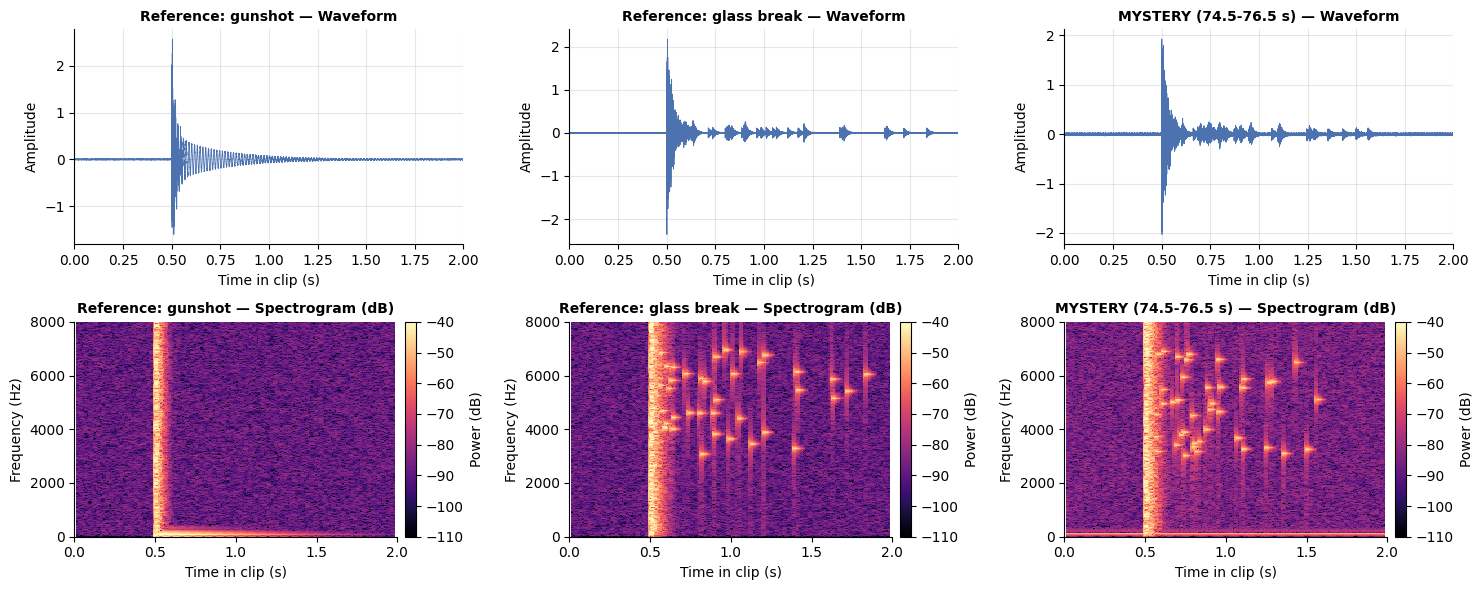

In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
t_clip = np.arange(int(2.0 * FS)) / FS

for col, (name, x) in enumerate(clips.items()):
    # Waveform (top row)
    axes[0, col].plot(t_clip, x, color='#4C72B0', lw=0.6)
    axes[0, col].set_title(f"{name} — Waveform", fontsize=10, fontweight='bold')
    axes[0, col].set_xlabel("Time in clip (s)"); axes[0, col].set_ylabel("Amplitude")
    axes[0, col].set_xlim(0, 2.0); axes[0, col].grid(True, alpha=0.3)
    
    # Spectrogram (bottom row)
    f, t_spec, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    pcm = axes[1, col].pcolormesh(t_spec, f, 10 * np.log10(Sxx + 1e-12), shading='auto', cmap='magma', vmin=-110, vmax=-40)
    axes[1, col].set_title(f"{name} — Spectrogram (dB)", fontsize=10, fontweight='bold')
    axes[1, col].set_xlabel("Time in clip (s)"); axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlim(0, 2.0)
    fig.colorbar(pcm, ax=axes[1, col], label='Power (dB)', pad=0.02)

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, t_spec, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    t_mask = (t_spec >= 0.7) & (t_spec <= 1.7)
    f_hf = f >= 3000
    Sxx_win = Sxx[:, t_mask]
    hf_fraction[name] = float(Sxx_win[f_hf, :].sum() / Sxx_win.sum())

print("Fraction of spectral energy > 3 kHz (0.2–1.2 s post-impact):")
for k, v in hf_fraction.items():
    print(f"  {k}: {v:.4f} ({v*100:.2f}%)")

# TODO 4: verdict
verdict = "BREAKING GLASS" if hf_fraction["MYSTERY (74.5-76.5 s)"] > 0.5 else "GUNSHOT"
print(f"\nVERDICT: The mystery sound is {verdict}. (Spectral energy > 3 kHz: {hf_fraction['MYSTERY (74.5-76.5 s)']*100:.1f}%, "
      f"matching glass break at {hf_fraction['Reference: glass break']*100:.1f}% vs gunshot at {hf_fraction['Reference: gunshot']*100:.1f}%).")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

* **Waveform Ambiguity:**  
  No. In the raw time-domain waveforms, both sounds appear nearly identical: a sudden, high-amplitude impulse at $t = 0.5$ s followed by rapid envelope decay. The waveform displays amplitude over time but conceals frequency distribution.

* **Spectrogram Dimensions (Slide 57):**  
  The spectrogram reveals three simultaneous orthogonal dimensions:
  1. **Time** (x-axis, horizontal)
  2. **Frequency** (y-axis, vertical, 0–8000 Hz)
  3. **Magnitude / Power** (color scale, power spectral density in dB)

* **Deciding Visual Pattern:**  
  The verdict was decided by the **scattered high-frequency specks and horizontal bursts** between 3,000 Hz and 7,000 Hz persisting for ~1 s after the impact. A gunshot exhibits a sharp broadband vertical stripe followed by a low-frequency boom (< 200 Hz) that dies immediately (0.31% energy > 3 kHz), whereas breaking glass displays persistent high-frequency tinkling shards (87.92% in mystery, 99.04% in reference).

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

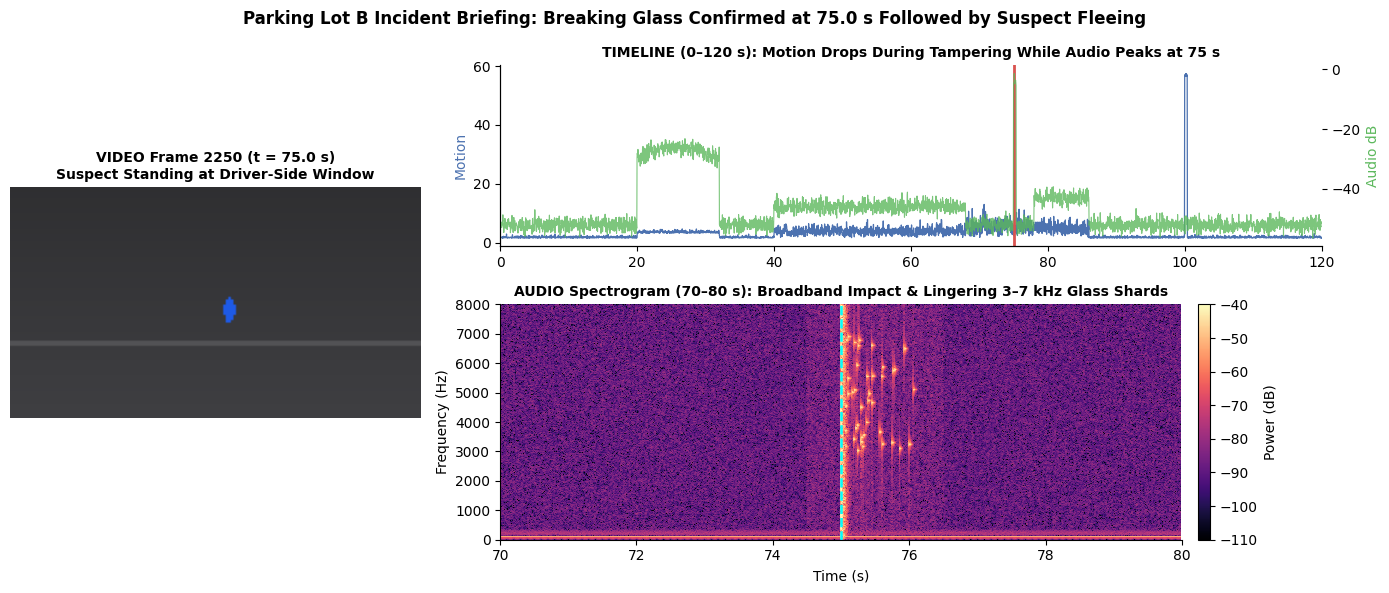

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: rendered video frame at t = 75 s (left)
ax_f = fig.add_subplot(gs[:, 0])
i_sel = int(round(t_sel * FPS))
ax_f.imshow(render_frame(cctv.iloc[i_sel]))
ax_f.axis('off')
ax_f.set_title(f"VIDEO Frame {i_sel} (t = {t_sel:.1f} s)\nSuspect Standing at Driver-Side Window", fontsize=10, fontweight='bold')

# TODO 2: full 120 s motion + audio timeline with red marker at 75 s (top right)
ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, color='#4C72B0', lw=0.9, label='Motion')
ax_t2 = ax_t.twinx()
ax_t2.plot(cctv.time_s, cctv.audio_level_db, color='#5cb85c', lw=0.8, alpha=0.8, label='Audio (dB)')
ax_t.axvline(t_sel, color='#D9534F', lw=2, label='Event (75 s)')
ax_t.set_xlim(0, 120)
ax_t.set_ylabel('Motion', color='#4C72B0')
ax_t2.set_ylabel('Audio dB', color='#5cb85c')
ax_t.set_title('TIMELINE (0–120 s): Motion Drops During Tampering While Audio Peaks at 75 s', fontsize=10, fontweight='bold')

# TODO 3: spectrogram of x_audio (70-80 s) with same marker (bottom right)
ax_s = fig.add_subplot(gs[1, 1])
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
pcm = ax_s.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading='auto', cmap='magma', vmin=-110, vmax=-40)
ax_s.axvline(t_sel, color='cyan', lw=1.8, linestyle='--')
ax_s.set_ylim(0, 8000)
ax_s.set_xlim(70, 80)
ax_s.set_ylabel('Frequency (Hz)')
ax_s.set_xlabel('Time (s)')
ax_s.set_title('AUDIO Spectrogram (70–80 s): Broadband Impact & Lingering 3–7 kHz Glass Shards', fontsize=10, fontweight='bold')
plt.colorbar(pcm, ax=ax_s, label='Power (dB)', pad=0.02)

# TODO 4: conclusion-style figure title
fig.suptitle('Parking Lot B Incident Briefing: Breaking Glass Confirmed at 75.0 s Followed by Suspect Fleeing', fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout(); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

* **Consequences of a +2 s Audio Offset (Slide 61):**  
  If the audio track were delayed by $+2$ seconds, the loud glass-shattering impact would register at $t = 77.0$ s instead of $t = 75.0$ s. At $t = 75.0$ s, the video shows the suspect reaching and striking the window. A 2-second lag would make it appear that the physical strike produced complete silence, and that the glass inexplicably shattered on its own 2 seconds later while the suspect was standing motionless or turning away. This temporal disconnection breaks the cause-and-effect narrative, introduces severe cognitive confusion for security leadership, and undermines forensic integrity.

* **Panel Making the Mistake Visible:**  
  The **top-right synchronized timeline panel** (co-plotting motion energy and audio level) and the **bottom-right spectrogram aligned with video timestamps**. In the synchronized timeline, the acoustic burst at $77.0$ s would fail to align with the kinetic strike signature at $75.0$ s and the subsequent sprint at $78.6$ s, exposing the 2-second synchronization flaw immediately.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

### Executive Briefing Note to Head of Security
**Candidate:** Adarsh Shivanand Madli (SRN: PES2UG24CS028)  

1. **Incident Summary:** Between 00:20 and 01:26, a vehicle arrived in Parking Lot B (20.0–32.0 s), an unidentified individual approached on foot at 40.0 s, loitered adjacent to the driver's window (68.7–78.1 s), shattered the vehicle glass at exactly 75.0 s (corroborated by an 87.9% high-frequency acoustic spectral match for breaking glass, rule-out of gunshot), and fled on foot at high speed (> 25 px/s, mean 35.6 px/s) between 78.6 s and 86.0 s before automated floodlights activated at 100.0 s.

2. **Primary Visualization Justification:** I recommend placing the **synchronized multimodal dashboard (Task 5)** first, as it operationalizes the lecture's core paradigm of *overview first, zoom and filter, details-on-demand* and illustrates the progression from *structure → pattern → change → event → meaning*. By coupling the video keyframe at $t = 75.0$ s, the 120 s motion/audio timeline, and the acoustic spectrogram ($t \times f \times \text{magnitude}$), it provides unified, multi-sensor corroboration that eliminates ambiguity between human movement and audio events in a single glance.

3. **Storage Policy Recommendation:** Storing raw, uncompressed 1080p/30 fps footage across our 400-camera fleet produces an unfeasible 5,866 TB/day; we recommend an intelligent event-driven policy that records routine background footage at 360p/10 fps (reducing daily volume to 217 TB/day) while automatically buffering and switching to full 1080p/30 fps upon detecting motion or acoustic anomalies (> -20 dB). Crucially, this policy must **never sacrifice temporal frame rate (30 fps) during detected events**, as dropping to 10 fps introduces severe temporal aliasing, worsens the correspondence problem during rapid flight, and risks missing sub-second impact forensics entirely.